# Neural Networks and Deep Learning — Lecture 3: Regularisation and generalisation
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies (ASE); Romanian Academy, Institute for Economic Forecasting (IPE)

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L3_notebook.ipynb)

This notebook reproduces the numbers and charts of the lecture from the real data in `../data/clean` (see `../data/SOURCES.md`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


In [3]:
import torch, torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
torch.set_num_threads(1)

class Net(nn.Module):
    def __init__(self, d, hidden=(128, 128), p=0.0, bn=False):
        super().__init__()
        layers, k = [], d
        for h in hidden:
            layers.append(nn.Linear(k, h))
            if bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p > 0:
                layers.append(nn.Dropout(p))
            k = h
        layers.append(nn.Linear(k, 1)); self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def fit(Xtr, ytr, Xva, yva, hidden=(128, 128), p=0.0, bn=False, wd=0.0, lr=1e-3, epochs=200, bs=128, seed=0,
        early=True, patience=20, loss='bce', opt_name='adam', record=False):
    """AdamW or SGD with momentum; dropout, batch norm, weight decay, early stopping on the validation loss"""
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = Net(Xtr.shape[1], hidden, p, bn)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd) if opt_name == 'adam' else torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    lf = nn.BCEWithLogitsLoss() if loss == 'bce' else nn.MSELoss()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
    Xv, yv = torch.tensor(Xva), torch.tensor(yva, dtype=torch.float32).view(-1, 1)
    best, state, bad, hist, best_ep = np.inf, None, 0, [], 0
    for ep in range(epochs):
        m.train(); idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]
            if len(b) < 2 and bn:
                continue
            opt.zero_grad(); lf(m(Xt[b]), yt[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            vl = float(lf(m(Xv), yv)); tl = float(lf(m(Xt), yt)) if record else np.nan
        hist.append((tl, vl))
        if not np.isfinite(vl):
            break
        if vl < best - 1e-5:
            best, bad, best_ep = vl, 0, ep + 1; state = {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if early and bad >= patience:
                break
    if early and state is not None:
        m.load_state_dict(state)
    m.eval()
    return m, hist, best_ep

def proba(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(torch.tensor(X))).numpy().ravel()

g = pd.read_csv(DATA + 'german_credit.csv'); yg = g['default'].values.astype(int); Xg_raw = g.drop(columns='default')
def encode_german(tr, others):
    cat = [c for c in tr.columns if tr[c].dtype == object]; num = [c for c in tr.columns if c not in cat]
    levels = {c: sorted(tr[c].unique()) for c in cat}
    def f(d):
        x = d[num].astype(float).copy()
        for c in cat:
            for lv in levels[c][1:]:
                x[f'{c}_{lv}'] = (d[c] == lv).astype(float)
        return x
    xtr = f(tr); mu, sd = xtr.mean(), xtr.std().replace(0, 1)
    return [((xtr - mu) / sd).values.astype(np.float32)] + [((f(o) - mu) / sd).values.astype(np.float32) for o in others]
g_tr, g_te = train_test_split(np.arange(len(g)), test_size=0.2, stratify=yg, random_state=SEED)
g_tr, g_va = train_test_split(g_tr, test_size=0.25, stratify=yg[g_tr], random_state=SEED)
Gtr, Gva, Gte = encode_german(Xg_raw.iloc[g_tr], [Xg_raw.iloc[g_va], Xg_raw.iloc[g_te]])

fr = pd.read_csv(DATA + 'creditcard_fraud_sample.csv').sort_values('Time').reset_index(drop=True)
Xf0 = np.c_[fr[[f'V{i}' for i in range(1, 29)]].values, np.log1p(fr['Amount'].values)].astype(np.float32)
yf = fr['Class'].values.astype(int); wf = fr['weight'].values; amt = fr['Amount'].values
c1, c2 = np.quantile(fr['Time'], [0.6, 0.8])
f_tr = (fr['Time'] <= c1).values; f_va = ((fr['Time'] > c1) & (fr['Time'] <= c2)).values; f_te = (fr['Time'] > c2).values
Xf = (Xf0 - Xf0[f_tr].mean(0)) / Xf0[f_tr].std(0)
ap = lambda y, p, w: float(average_precision_score(y, p, sample_weight=w))
print('German credit train/val/test:', len(g_tr), len(g_va), len(g_te), '| fraud train/val/test:', f_tr.sum(), f_va.sum(), f_te.sum(),
      '| frauds in test:', yf[f_te].sum())

German credit train/val/test: 600 200 200 | fraud train/val/test: 17354 5785 5785 | frauds in test: 75


## §1 Overfitting on 600 applicants

best validation epoch 3 | val loss min 0.536 | after 150 epochs 2.187


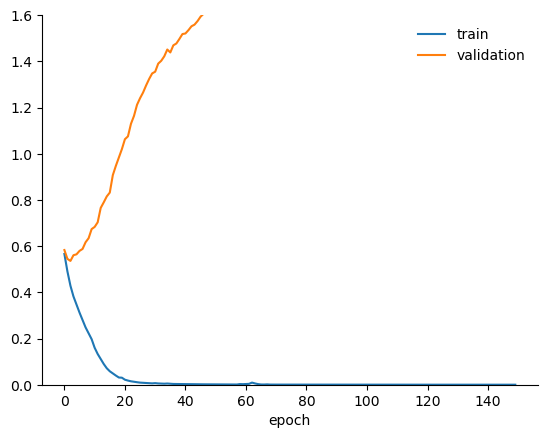

In [4]:
_, h, _ = fit(Gtr, yg[g_tr], Gva, yg[g_va], hidden=(256, 256), epochs=150, early=False, record=True, bs=64)
h = np.array(h); print('best validation epoch', int(np.argmin(h[:, 1]) + 1), '| val loss min', round(h[:, 1].min(), 3), '| after 150 epochs', round(h[-1, 1], 3))
plt.plot(h[:, 0], label='train'); plt.plot(h[:, 1], label='validation'); plt.ylim(0, 1.6); plt.legend(); plt.xlabel('epoch'); plt.show()

## §2 Double descent with random ReLU features

In [5]:
ca = pd.read_csv(DATA + 'california_housing.csv'); Xc = ca.drop(columns='MedHouseVal_100k_usd').values; yc = ca['MedHouseVal_100k_usd'].values
rng = np.random.default_rng(SEED); idx = rng.permutation(len(Xc)); tr, te = idx[:400], idx[400:5400]
mu, sd = Xc[tr].mean(0), Xc[tr].std(0); A, B = (Xc[tr] - mu) / sd, (Xc[te] - mu) / sd
Wr = rng.normal(0, 1 / np.sqrt(8), (8, 8000)); br = rng.normal(0, 1, 8000)
for p in (50, 200, 400, 800, 8000):
    Fa, Fb = np.maximum(A @ Wr[:, :p] + br[:p], 0), np.maximum(B @ Wr[:, :p] + br[:p], 0); yt = yc[tr] - yc[tr].mean()
    beta = np.linalg.lstsq(Fa, yt, rcond=None)[0] if p <= 400 else Fa.T @ np.linalg.lstsq(Fa @ Fa.T, yt, rcond=None)[0]
    print(p, 'test MSE', round(np.mean((Fb @ beta + yc[tr].mean() - yc[te]) ** 2), 3))

50 test MSE 397.83
200 test MSE 92237.066
400 test MSE 229705628.577
800 test MSE 15.274


8000 test MSE 124.273


## §3 L1 against L2 penalties

In [6]:
def penal_net(kind, lam, epochs=300):
    torch.manual_seed(SEED); m = Net(Gtr.shape[1], (64,)); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    Xt, yt = torch.tensor(Gtr), torch.tensor(yg[g_tr], dtype=torch.float32).view(-1, 1)
    for ep in range(epochs):
        opt.zero_grad(); W = m.net[0].weight
        (nn.BCEWithLogitsLoss()(m(Xt), yt) + lam * (W.abs().sum() if kind == 'l1' else (W ** 2).sum())).backward(); opt.step()
    return m.eval()
for kind, lam in (('l1', 1e-3), ('l2', 1e-2)):
    w = penal_net(kind, lam).net[0].weight.detach().numpy().ravel(); print(kind, 'share of |w| < 0.01:', round(100 * np.mean(np.abs(w) < 0.01), 1), '%')

l1 share of |w| < 0.01: 67.2 %


l2 share of |w| < 0.01: 26.3 %


## §4 Weight decay and dropout under cross-validation

In [7]:
FD = []
for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xg_raw, yg):
    a_tr, a_va = train_test_split(a, test_size=0.2, stratify=yg[a], random_state=SEED)
    xa, xv, xb = encode_german(Xg_raw.iloc[a_tr], [Xg_raw.iloc[a_va], Xg_raw.iloc[b]]); FD.append((xa, yg[a_tr], xv, yg[a_va], xb, yg[b]))
run = lambda f, **kw: roc_auc_score(FD[f][5], proba(fit(*FD[f][:4], hidden=(256, 256), epochs=150, bs=64, early=False, seed=f, **kw)[0], FD[f][4]))
for kw in ({}, {'wd': 1.0}, {'p': 0.5}):
    print(kw, 'mean held-out AUC', round(np.mean([run(f, **kw) for f in range(5)]), 3))
print('logistic', round(np.mean([roc_auc_score(FD[f][5], LogisticRegression(C=1.0, max_iter=5000).fit(FD[f][0], FD[f][1]).predict_proba(FD[f][4])[:, 1]) for f in range(5)]), 3))

{} mean held-out AUC 0.749


{'wd': 1.0} mean held-out AUC 0.75


{'p': 0.5} mean held-out AUC 0.753
logistic 0.772


§ Experiment yourself: replace `hidden=(256, 256)` by `hidden=(16,)` and compare with logistic regression.

## §5 Early stopping on card fraud

best validation epoch 4 | validation loss there 0.0159 | at the end 0.0593


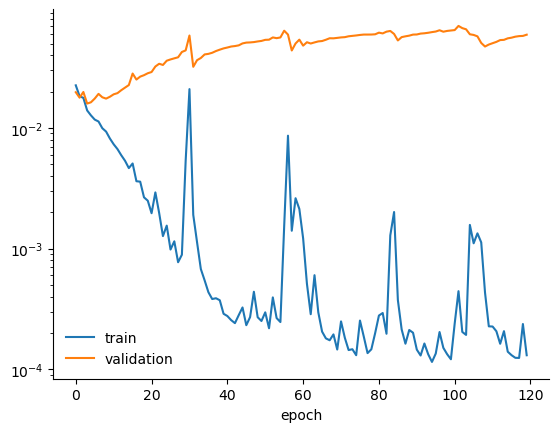

In [8]:
_, h, best = fit(Xf[f_tr], yf[f_tr], Xf[f_va], yf[f_va], hidden=(256, 256), epochs=120, early=False, record=True, bs=256)
h = np.array(h); print('best validation epoch', int(np.argmin(h[:, 1]) + 1), '| validation loss there', round(h[:, 1].min(), 4), '| at the end', round(h[-1, 1], 4))
plt.semilogy(h[:, 0], label='train'); plt.semilogy(h[:, 1], label='validation'); plt.legend(); plt.xlabel('epoch'); plt.show()

## §6 Batch normalisation and the learning rate

In [9]:
ci_tr, ci_te = train_test_split(np.arange(len(ca)), test_size=0.2, random_state=SEED); ci_tr, ci_va = train_test_split(ci_tr, test_size=0.25, random_state=SEED)
Cz = ((Xc - Xc[ci_tr].mean(0)) / Xc[ci_tr].std(0)).astype(np.float32); y32 = yc.astype(np.float32)
for bn in (False, True):
    _, h, _ = fit(Cz[ci_tr], y32[ci_tr], Cz[ci_va], y32[ci_va], hidden=(64,) * 6, bn=bn, lr=0.1, epochs=40, bs=128, early=False, loss='mse', opt_name='sgd')
    v = [x[1] for x in h]; print('batch norm' if bn else 'no batch norm', '| epochs run', len(v), '| best validation MSE', round(np.nanmin(v), 3))

no batch norm | epochs run 3 | best validation MSE 1.279


batch norm | epochs run 40 | best validation MSE 0.283


## §7 Variability of a single hold-out split

AUC range 0.702 - 0.842 | 90% interval [0.743 0.816]


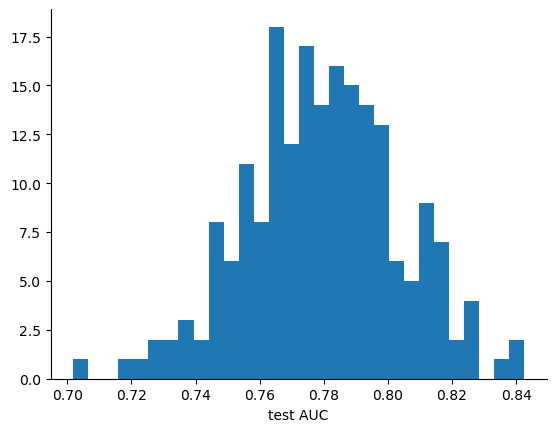

In [10]:
aucs = []
for s in range(200):
    a, b = train_test_split(np.arange(len(yg)), test_size=0.3, stratify=yg, random_state=SEED + s); xa, xb = encode_german(Xg_raw.iloc[a], [Xg_raw.iloc[b]])
    aucs.append(roc_auc_score(yg[b], LogisticRegression(C=1.0, max_iter=5000).fit(xa, yg[a]).predict_proba(xb)[:, 1]))
print('AUC range', round(min(aucs), 3), '-', round(max(aucs), 3), '| 90% interval', np.round(np.percentile(aucs, [5, 95]), 3))
plt.hist(aucs, bins=30); plt.xlabel('test AUC'); plt.show()

## §8 Validation design and leakage

In [11]:
res = {'time': [], 'random': [], 'oversample_first': []}
for s in range(3):
    m, _, _ = fit(Xf[f_tr], yf[f_tr], Xf[f_va], yf[f_va], hidden=(128, 128), epochs=40, bs=256, seed=s); res['time'].append(ap(yf[f_te], proba(m, Xf[f_te]), wf[f_te]))
    idx = np.arange(len(yf)); a, b = train_test_split(idx, test_size=0.2, stratify=yf, random_state=SEED + s); a, v = train_test_split(a, test_size=0.25, stratify=yf[a], random_state=SEED + s)
    Z = (Xf0 - Xf0[a].mean(0)) / Xf0[a].std(0); m, _, _ = fit(Z[a], yf[a], Z[v], yf[v], hidden=(128, 128), epochs=40, bs=256, seed=s); res['random'].append(ap(yf[b], proba(m, Z[b]), wf[b]))
    rng = np.random.default_rng(SEED + s); big = np.r_[idx, np.repeat(np.where(yf == 1)[0], 19)]; rng.shuffle(big); yb = yf[big]
    a, b = train_test_split(np.arange(len(big)), test_size=0.2, stratify=yb, random_state=SEED + s); a, v = train_test_split(a, test_size=0.25, stratify=yb[a], random_state=SEED + s)
    Xb = Xf0[big]; Z = (Xb - Xb[a].mean(0)) / Xb[a].std(0); m, _, _ = fit(Z[a], yb[a], Z[v], yb[v], hidden=(128, 128), epochs=40, bs=256, seed=s)
    res['oversample_first'].append(ap(yb[b], proba(m, Z[b]), np.where(yb == 1, 1 / 20, wf[big])[b]))
print({k: round(np.mean(v), 3) for k, v in res.items()})

{'time': np.float64(0.847), 'random': np.float64(0.849), 'oversample_first': np.float64(0.891)}


## §9 The fraud data: rare and clustered

fraud rate in the full data %: 0.173 | highest hourly rate %: 2.27


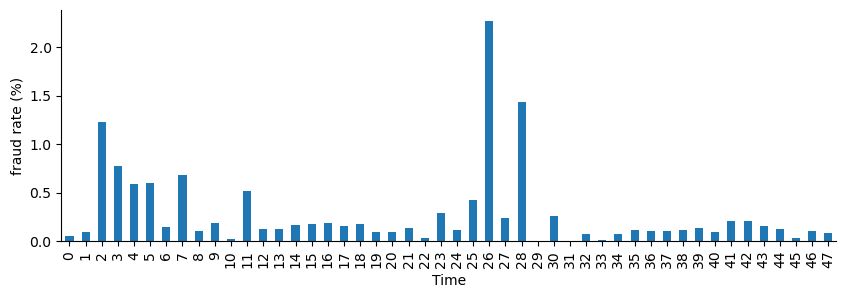

In [12]:
hour = (fr['Time'] // 3600).astype(int); rate = pd.Series(yf).groupby(hour).sum() / pd.Series(wf).groupby(hour).sum()
print('fraud rate in the full data %:', round(100 * yf.sum() / wf.sum(), 3), '| highest hourly rate %:', round(100 * rate.max(), 2))
(100 * rate).plot.bar(figsize=(10, 3)); plt.ylabel('fraud rate (%)'); plt.show()

## §10 Case study: regularised MLP, logistic regression and XGBoost on fraud

logistic test PR-AUC 0.789
MLP test PR-AUC 0.84
XGBoost test PR-AUC 0.814


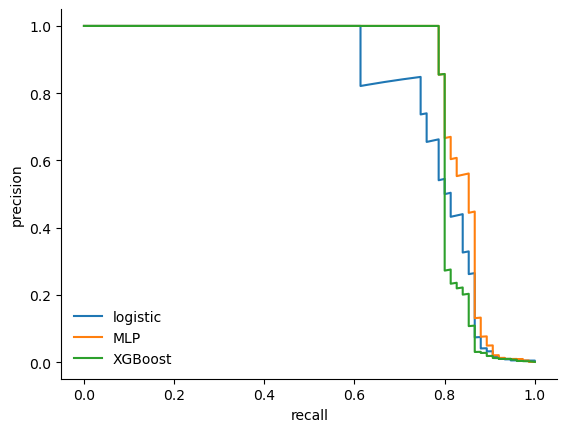

In [13]:
import xgboost as xgb   # on macOS start Jupyter with OMP_NUM_THREADS=1 if the kernel stops here
p_lr = LogisticRegression(max_iter=5000).fit(Xf[f_tr], yf[f_tr]).predict_proba(Xf[f_te])[:, 1]
p_ml = np.mean([proba(fit(Xf[f_tr], yf[f_tr], Xf[f_va], yf[f_va], hidden=(256, 256), epochs=60, bs=256, seed=s, wd=0.1, p=0.3)[0], Xf[f_te]) for s in range(5)], axis=0)
xgm = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, eval_metric='aucpr',
                        early_stopping_rounds=100, random_state=SEED, n_jobs=1)
xgm.fit(Xf[f_tr], yf[f_tr], eval_set=[(Xf[f_va], yf[f_va])], verbose=False); p_xg = xgm.predict_proba(Xf[f_te])[:, 1]
for nm, p in (('logistic', p_lr), ('MLP', p_ml), ('XGBoost', p_xg)):
    print(nm, 'test PR-AUC', round(ap(yf[f_te], p, wf[f_te]), 3))
    pr, rc, _ = precision_recall_curve(yf[f_te], p, sample_weight=wf[f_te]); plt.plot(rc, pr, label=nm)
plt.xlabel('recall'); plt.ylabel('precision'); plt.legend(); plt.show()